# Exploratory Data Analysis (EDA) on Google Drive Data

This notebook guides you through mounting your Google Drive, loading your dataset, and conducting a preliminary Exploratory Data Analysis (EDA).

In [1]:
from google.colab import drive
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Mount Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


### Locate Your File
Run the cell below to list the files in your Google Drive so you can copy the correct path to your dataset.

In [2]:
# List the files in the main directory of your Google Drive
drive_path = '/content/drive/My Drive/BOG'
if os.path.exists(drive_path):
    print("Files and folders in your Google Drive:")
    display(os.listdir(drive_path))
else:
    print("Drive is not mounted yet or path is incorrect.")

Files and folders in your Google Drive:


['Features.csv',
 'feature_dictionary.csv',
 'loan_month_recovery.csv',
 'ამოცანის პირობა.docx',
 'feature_dictionary.gsheet',
 'hopeless_loans_eda.ipynb',
 'logistic_regression.ipynb',
 'Dummy_Benchmark.ipynb',
 'Light_GBM.ipynb',
 'Ridge_Regression.ipynb']

### Load dataset
Replace `path_to_your_file.csv` with the actual path to your file (for example: `/content/drive/My Drive/dataset.csv`). If you have an Excel file, use `pd.read_excel()` instead.

In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 100); pd.set_option('display.max_colwidth', 160)

DATA_DIR      = Path('/content/drive/My Drive/BOG/')    # <- folder with the 3 CSVs
FEE_MODE      = 'client'     # 'client' = 500 per client | 'loan' = 500 per loan
FIXED_FEE     = 500
VAR_FEE       = 0.10         # share of outstanding
EXCLUDE_MIXED = False        # True = drop clients that also hold secured loans
M = [f'M{i:02d}_PAID' for i in range(1, 25)]

In [ ]:
rec  = pd.read_csv(DATA_DIR / 'loan_month_recovery.csv')
feat = pd.read_csv(DATA_DIR / 'Features.csv').rename(columns={'client_key': 'CLIENT_KEY'})
dic  = pd.read_csv(DATA_DIR / 'feature_dictionary.csv').set_index('column')
FC   = [c for c in feat.columns if c.startswith('feature_')]

for name, d in [('recovery', rec), ('features', feat), ('dictionary', dic)]:
    print(name, d.shape)
display(rec.head())
display(feat.iloc[:, :12].head())
display(dic)

### Integrity Checks

In [ ]:
print('duplicate LOAN_KEY:', rec.LOAN_KEY.duplicated().sum())
print('clients:', rec.CLIENT_KEY.nunique(),
      '| client-periods:', rec[['CLIENT_KEY', 'PERIOD']].drop_duplicates().shape[0])
print('clients appearing in >1 period:', (rec.groupby('CLIENT_KEY').PERIOD.nunique() > 1).sum())

nn  = rec[M].notna().sum(axis=1)
arr = rec[M].notna().values
print('non-null months == MONTHS_OBSERVED:', (nn == rec.MONTHS_OBSERVED).mean())
print('rows with gaps in payment months  :', (~(arr[:, :-1] >= arr[:, 1:]).all(axis=1)).sum())
print('negative payments                 :', (rec[M] < 0).sum().sum())
print('loans with OUTST <= 0             :', (rec.OUTST_AT_TRIAL <= 0).sum())
print('loans with OUTST > principal      :', (rec.OUTST_AT_TRIAL > rec.DEAL_PRINCIPAL_IN_GEL).sum())

cp = rec[['CLIENT_KEY', 'PERIOD']].drop_duplicates()
print('\nJoin coverage recovery vs features:')
print(cp.merge(feat[['CLIENT_KEY', 'PERIOD']], how='outer', indicator=True)._merge.value_counts())
print('duplicate client-period in features:', feat.duplicated(['CLIENT_KEY', 'PERIOD']).sum())

### Loan Composition

In [ ]:
print(rec.DEAL_CCY.value_counts(), '\n')
print(rec.groupby('DEAL_CCY')[['OUTST_AT_TRIAL', 'DEAL_PRINCIPAL_IN_GEL']].median(), '\n')
print(pd.crosstab(rec.COLLATERAL_TYPE, rec.HAS_COLLATERAL), '\n')
print(rec.OUTST_AT_TRIAL.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]))

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
rec.groupby('PERIOD').size().plot(ax=ax[0], title='Loans per PERIOD')
np.log10(rec.OUTST_AT_TRIAL.clip(lower=1)).hist(bins=60, ax=ax[1]); ax[1].set_title('log10(OUTST_AT_TRIAL)')
rec.MONTHS_OBSERVED.value_counts().sort_index().plot.bar(ax=ax[2], title='MONTHS_OBSERVED')
plt.tight_layout(); plt.show()

g = rec.groupby(['CLIENT_KEY', 'PERIOD']).agg(n_loans=('LOAN_KEY', 'size'),
                                              min_col=('HAS_COLLATERAL', 'min'),
                                              max_col=('HAS_COLLATERAL', 'max'))
print('\nclient-periods | all unsecured:', (g.max_col == 0).sum(),
      '| all secured:', (g.min_col == 1).sum(),
      '| mixed:', ((g.min_col == 0) & (g.max_col == 1)).sum())
print(g.n_loans.value_counts().sort_index())

### Payment Profile

In [ ]:
# unsecured loans with positive balance; "matured" = full 24 months observed
L  = rec[(rec.HAS_COLLATERAL == 0) & (rec.OUTST_AT_TRIAL > 0)]
Lm = L[L.MONTHS_OBSERVED == 24]

prof = Lm[M].sum() / Lm.OUTST_AT_TRIAL.sum()
cum  = prof.cumsum()
print(f'matured unsecured loans: {len(Lm):,} | pooled 24m recovery: {cum.iloc[-1]:.1%}')
print(f'share of 24m recovery arriving after m6 : {prof.iloc[6:].sum() / prof.sum():.1%}')
print(f'share of 24m recovery arriving after m12: {prof.iloc[12:].sum() / prof.sum():.1%}')

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
(prof * 100).plot.bar(ax=ax[0], title='Monthly recovery, % of outstanding')
(cum * 100).plot(ax=ax[1], marker='o', title='Cumulative recovery, % of outstanding')
plt.tight_layout(); plt.show()

# secured vs unsecured (includes censored loans, so read it relatively, not absolutely)
rec['paid_obs'] = rec[M].sum(axis=1)
sec = (rec[rec.OUTST_AT_TRIAL > 0].groupby('COLLATERAL_TYPE')
       .agg(loans=('LOAN_KEY', 'size'),
            zero_share=('paid_obs', lambda s: (s == 0).mean()),
            paid=('paid_obs', 'sum'), outst=('OUTST_AT_TRIAL', 'sum')))
sec['pooled_rr_observed'] = sec.paid / sec.outst
display(sec.round(3))

### Client-Level Dataset, Target and Economics

In [ ]:
rec['p6']  = rec[M[:6]].sum(axis=1)
rec['p12'] = rec[M[:12]].sum(axis=1)
rec['p24'] = rec[M].sum(axis=1)

L = rec[(rec.HAS_COLLATERAL == 0) & (rec.OUTST_AT_TRIAL > 0)]
cl = (L.groupby(['CLIENT_KEY', 'PERIOD'])
        .agg(outst=('OUTST_AT_TRIAL', 'sum'), n_loans=('LOAN_KEY', 'size'),
             p6=('p6', 'sum'), p12=('p12', 'sum'), p24=('p24', 'sum'),
             mo=('MONTHS_OBSERVED', 'min')).reset_index())
has_sec = rec.groupby(['CLIENT_KEY', 'PERIOD']).HAS_COLLATERAL.max().rename('has_secured').reset_index()
cl = cl.merge(has_sec, on=['CLIENT_KEY', 'PERIOD'])
if EXCLUDE_MIXED:
    cl = cl[cl.has_secured == 0]

fee_units = cl.n_loans if FEE_MODE == 'loan' else 1
cl['cost']         = FIXED_FEE * fee_units + VAR_FEE * cl.outst
cl['breakeven_rr'] = cl.cost / cl.outst
cl['rr24']         = cl.p24 / cl.outst
cl['net24']        = cl.p24 - cl.cost          # only meaningful when mo == 24
mat = cl[cl.mo == 24].copy()

print(f'client-periods: {len(cl):,} | matured (24m): {len(mat):,} | fee mode: {FEE_MODE}')
print('breakeven recovery-rate quantiles:', cl.breakeven_rr.quantile([.1, .25, .5, .75, .9]).round(2).to_dict())
print(f'share needing >50% recovery: {(cl.breakeven_rr > .5).mean():.1%} | >90%: {(cl.breakeven_rr > .9).mean():.1%}')
print(f'zero-recovery share (matured): {(mat.p24 == 0).mean():.1%}')
print(f'avg cost {mat.cost.mean():,.0f} | avg recovery {mat.p24.mean():,.0f}')
print(f'profitable share: {(mat.net24 > 0).mean():.1%}')
print(f'net if we sue everyone: {mat.net24.sum():,.0f} | oracle (sue only profitable): {mat.net24.clip(lower=0).sum():,.0f}')

mat['bucket'] = pd.cut(mat.outst, [0, 2000, 4000, 8000, 15000, np.inf])
tab = (mat.groupby('bucket', observed=True)
          .agg(n=('net24', 'size'), zero_share=('p24', lambda s: (s == 0).mean()),
               profitable=('net24', lambda s: (s > 0).mean()), mean_net=('net24', 'mean'),
               oracle=('net24', lambda s: s.clip(lower=0).sum())))
tab['oracle_share'] = tab.oracle / tab.oracle.sum()
display(tab.round(3))
display(mat.groupby('n_loans').agg(n=('net24', 'size'), profitable=('net24', lambda s: (s > 0).mean()),
                                   mean_net=('net24', 'mean')).round(3))

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
mat.rr24.hist(bins=50, ax=ax[0]); ax[0].set_title('24m recovery rate (matured)')
cl.breakeven_rr.clip(upper=1.5).hist(bins=50, ax=ax[1]); ax[1].set_title('Breakeven recovery rate (clipped at 1.5)')
tab.profitable.plot.bar(ax=ax[2], title='Share profitable by outstanding bucket')
plt.tight_layout(); plt.show()

### Vintage Drift

In [ ]:
cl['quarter'] = pd.PeriodIndex(cl.PERIOD.str.replace('/', '-'), freq='Q').astype(str)
v = (cl.groupby('quarter')
       .agg(n=('outst', 'size'), mean_outst=('outst', 'mean'),
            zero6=('p6', lambda s: (s == 0).mean()), p6=('p6', 'sum'), outst=('outst', 'sum')))
v['pooled_6m_rr'] = v.p6 / v.outst
display(v.drop(columns=['p6', 'outst']).round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
v.pooled_6m_rr.plot(ax=ax[0], marker='o', title='Pooled 6m recovery rate by quarter')
v.n.plot.bar(ax=ax[1], title='Unsecured client-periods per quarter')
plt.tight_layout(); plt.show()

### Feature Profiling

In [ ]:
fp = pd.DataFrame({
    'group': dic.group.reindex(FC), 'unit': dic.unit.reindex(FC),
    'miss_pct': feat[FC].isna().mean() * 100, 'nunique': feat[FC].nunique(),
    'min': feat[FC].min(), 'p50': feat[FC].median(),
    'p99': feat[FC].quantile(.99), 'max': feat[FC].max(), 'skew': feat[FC].skew()})
display(fp.round(2))

print('rows with any missing value:', f"{feat[FC].isna().any(axis=1).mean():.1%}")
print('constant features:', fp.index[fp.nunique == 1].tolist() if hasattr(fp, 'nunique') and False else fp.index[fp['nunique'] == 1].tolist())
ratio = [c for c in FC if dic.loc[c, 'unit'] == 'ratio 0-1']
print('ratio features outside [0,1]:', [c for c in ratio if ((feat[c] < 0) | (feat[c] > 1)).any()])
binary = [c for c in FC if dic.loc[c, 'unit'] == '0/1']
print('binary features with other values:', [c for c in binary if not set(feat[c].dropna().unique()) <= {0, 1}])

### Features vs Target and The Leakage Check

In [ ]:
mf = mat.merge(feat, on=['CLIENT_KEY', 'PERIOD'])
mf['any24'] = (mf.p24 > 0).astype(int)

rows = []
for c in FC:
    x = mf[c]; ok = x.notna()
    if x.nunique() < 2:
        continue
    rows.append((c, spearmanr(x[ok], mf.rr24[ok])[0], roc_auc_score(mf.any24[ok], x[ok])))
sig = pd.DataFrame(rows, columns=['feature', 'rho_rr24', 'auc_any24']).set_index('feature')
sig['group'] = dic.group
sig = sig.reindex(sig.rho_rr24.abs().sort_values(ascending=False).index)
display(sig.head(20).round(3))

print('\nTop feature description:', dic.loc[sig.index[0], 'description'])
print('Any feature whose description mentions "after" enforcement:')
display(dic[dic.description.str.contains('after', case=False)])

### Redundancy, Missingness, Drift, Repeat Clients

In [ ]:
C = feat[FC].corr(method='spearman').abs()
C = C.where(~np.eye(len(C), dtype=bool), 0)
pairs = [(a, b, round(C.loc[a, b], 3)) for i, a in enumerate(FC) for b in FC[i + 1:] if C.loc[a, b] > 0.6]
print('correlated pairs (|rho| > 0.6):', sorted(pairs, key=lambda t: -t[2]))
print('feature_017 == feature_033 share:', (feat.feature_017 == feat.feature_033).mean())

print('\nInformative missingness (matured unsecured clients):')
for c in ['feature_011', 'feature_039']:
    m = mf[c].isna()
    print(f"{c}: missing {m.mean():.1%} | P(any payment) missing/present = "
          f"{mf.any24[m].mean():.3f}/{mf.any24[~m].mean():.3f} | pooled rr24 = "
          f"{mf.p24[m].sum() / mf.outst[m].sum():.3f}/{mf.p24[~m].sum() / mf.outst[~m].sum():.3f}")

feat['year'] = feat.PERIOD.str[:4]
early, late = feat[feat.year == '2023'], feat[feat.year == '2025']
shift = ((late[FC].mean() - early[FC].mean()) / feat[FC].std()).abs().sort_values(ascending=False)
print('\nLargest standardized mean shift 2023 -> 2025:'); print(shift.head(6).round(3))

print('\nclients in >1 period:', (rec.groupby('CLIENT_KEY').PERIOD.nunique() > 1).sum(), 'of', rec.CLIENT_KEY.nunique())

### Feature hygine


In [ ]:
import seaborn as sns
from scipy.stats import spearmanr, pearsonr, kruskal, mannwhitneyu, chi2_contingency
from sklearn.metrics import roc_auc_score
from sklearn.feature_selection import mutual_info_regression
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.proportion import proportion_confint

# ---- 1. Feature hygiene -------------------------------------------------------
LEAK  = ['feature_045']                      # description: measured in the 12 months AFTER enforcement start
const = [c for c in FC if feat[c].nunique(dropna=True) < 2]
dups  = [c for i, a in enumerate(FC) for c in FC[i+1:] if feat[a].equals(feat[c])]   # exact duplicates
print('leakage      :', LEAK, '->', dic.loc[LEAK[0], 'description'])
print('constant     :', const)
print('exact dupes  :', dups, '(feature_017 and feature_033 are identical)')

USE = [c for c in FC if c not in LEAK + const + dups]
print(f'features kept for modelling: {len(USE)} of {len(FC)}')

mf = mat.merge(feat, on=['CLIENT_KEY', 'PERIOD'])
mf['any24']  = (mf.p24 > 0).astype(int)
mf['profit'] = (mf.net24 > 0).astype(int)

# why 045 must go: it is not just 'a strong feature'
print('\nfeature_045 vs target  | spearman(rr24): %.2f | AUC(profit): %.2f' %
      (spearmanr(mf.feature_045, mf.rr24)[0], roc_auc_score(mf.profit, mf.feature_045)))
print('best legitimate feature | spearman(rr24): %.2f' %
      max(abs(spearmanr(mf[c], mf.rr24, nan_policy='omit')[0]) for c in USE))

### Target Distribution

In [ ]:
# ---- 2. Target distribution (zero-inflated) -----------------------------------------
y = mf.rr24
payers = mf[mf.any24 == 1]
print(f'zero recovery: {(y==0).mean():.1%} | any payment: {mf.any24.mean():.1%} | profitable: {mf.profit.mean():.1%}')
print(f'rr24 skew: {y.skew():.2f} | among payers: median {payers.rr24.median():.3f}, mean {payers.rr24.mean():.3f}')
print(f'profitable among payers: {payers.profit.mean():.1%}')
print(y.quantile([.5, .75, .9, .95, .99]).round(3).to_dict())

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
y.hist(bins=50, ax=ax[0]); ax[0].set_title('rr24: all matured clients (spike at 0)')
payers.rr24.hist(bins=50, ax=ax[1]); ax[1].set_title('rr24: payers only')
np.log10(mf.outst).groupby(mf.profit).plot.kde(ax=ax[2], legend=True)
ax[2].set_title('log10(outstanding) by profitable (1) / not (0)')
plt.tight_layout(); plt.show()

### Mixed Clients vs Purely Unsecured Clients

In [ ]:
# ---- 3. Mixed clients vs purely unsecured clients ------------------------------------
# cl/mat only keep the UNSECURED loans of a client, but some clients ALSO hold secured loans.
g = mf.groupby('has_secured').agg(n=('rr24', 'size'), any_payment=('any24', 'mean'),
                                  mean_rr24=('rr24', 'mean'), profitable=('profit', 'mean'))
display(g.round(3))
ct = pd.crosstab(mf.has_secured, mf.any24)
print('chi2 p-value (any payment vs has_secured): %.2e' % chi2_contingency(ct)[1])
print('Mann-Whitney p (rr24): %.2e' % mannwhitneyu(mf.rr24[mf.has_secured == 1], mf.rr24[mf.has_secured == 0]).pvalue)

# inside mixed clients: do secured and unsecured loans recover at the same rate?
mixed_keys = mf.loc[mf.has_secured == 1, ['CLIENT_KEY', 'PERIOD']]
r = rec.merge(mixed_keys, on=['CLIENT_KEY', 'PERIOD'])
r = r[r.MONTHS_OBSERVED == 24]
x = r.groupby('HAS_COLLATERAL').agg(loans=('LOAN_KEY', 'size'), zero_share=('p24', lambda s: (s == 0).mean()),
                                    pooled_rr=('p24', 'sum'), outst=('OUTST_AT_TRIAL', 'sum'))
x['pooled_rr'] = x.pooled_rr / x.outst
display(x.round(3))
print('If secured and unsecured loans of the same client recover at the same rate, payments are probably\n'
      'allocated across ALL of the client\'s loans (e.g. from collateral sale) -> their unsecured recovery is\n'
      'not a clean signal for the unsecured-only use case. Consider EXCLUDE_MIXED = True.')

### Feature vs Target

,group,coverage,pearson,spearman,auc_any,auc_profit,mutual_info,q_fdr,ci_lo,ci_hi
feature,,,,,,,,,,
feature_031,credit bureau history,1.000,0.169,0.170,0.579,0.610,0.011,0.0,0.153,0.190
feature_034,credit bureau history,1.000,0.170,0.167,0.577,0.612,0.016,0.0,0.145,0.184
feature_019,repayment history on other loans,1.000,-0.143,-0.142,0.436,0.403,0.010,0.0,-0.159,-0.125
feature_011,account balances,0.143,0.110,0.140,0.555,0.579,0.015,0.0,0.087,0.180
feature_012,account balances,1.000,0.094,0.127,0.556,0.589,0.001,0.0,0.110,0.143
feature_021,repayment history on other loans,1.000,-0.097,-0.108,0.449,0.435,0.004,0.0,-0.126,-0.089
feature_018,repayment history on other loans,1.000,0.109,0.105,0.547,0.572,0.000,0.0,0.087,0.119
feature_014,account balances,1.000,0.082,0.098,0.540,0.573,0.000,0.0,0.082,0.116
feature_017,repayment history on other loans,1.000,0.104,0.097,0.533,0.559,0.006,0.0,0.080,0.116


features significant after Benjamini-Hochberg (q<0.05): 29 of 47
max |spearman| = 0.170 | max AUC(any payment) distance from 0.5 = 0.079
=> with n=11560 even tiny correlations are significant; judge by EFFECT SIZE, not p-values.

Strongest feature per group:


,spearman,auc_any,feature
group,,,
account balances,0.140,0.555,feature_011
credit bureau history,0.170,0.579,feature_031
declared income,0.091,0.535,feature_039
digital channel usage,0.048,0.519,feature_026
recent credit applications,-0.013,0.492,feature_046
repayment history on other loans,-0.142,0.436,feature_019
transaction activity,0.079,0.536,feature_003


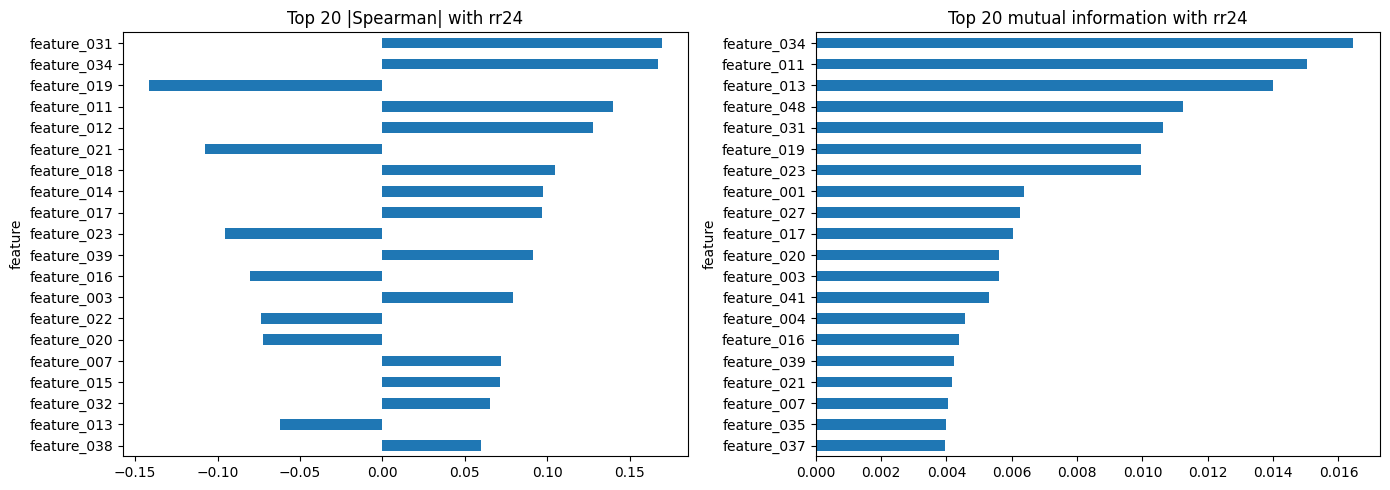

In [ ]:
# ---- 4. Feature vs target ---------------------------------------------------------------
rng = np.random.default_rng(0)
Xmed = mf[USE].fillna(mf[USE].median())
mi = pd.Series(mutual_info_regression(Xmed, mf.rr24, random_state=0), index=USE)

rows = []
for c in USE:
    ok = mf[c].notna(); x = mf.loc[ok, c]
    rho, p = spearmanr(x, mf.rr24[ok])
    rows.append(dict(feature=c, group=dic.group[c], coverage=ok.mean(),
                     pearson=pearsonr(x, mf.rr24[ok])[0], spearman=rho, p=p,
                     auc_any=roc_auc_score(mf.any24[ok], x), auc_profit=roc_auc_score(mf.profit[ok], x),
                     mutual_info=mi[c]))
S = pd.DataFrame(rows).set_index('feature')
S['q_fdr'] = multipletests(S.p, method='fdr_bh')[1]
S = S.reindex(S.spearman.abs().sort_values(ascending=False).index)

# bootstrap 95% CI of Spearman for the top 20
def boot_ci(c, B=300):
    ok = mf[c].notna().values; x = mf.loc[ok, c].values; yy = mf.rr24.values[ok]
    vals = [spearmanr(x[i], yy[i])[0] for i in (rng.integers(0, len(x), len(x)) for _ in range(B))]
    return np.percentile(vals, [2.5, 97.5])
for c in S.index[:20]:
    S.loc[c, 'ci_lo'], S.loc[c, 'ci_hi'] = boot_ci(c, B=200)

display(S.drop(columns='p').head(20).round(3))
print(f'features significant after Benjamini-Hochberg (q<0.05): {(S.q_fdr < .05).sum()} of {len(S)}')
print(f'max |spearman| = {S.spearman.abs().max():.3f} | max AUC(any payment) distance from 0.5 = {(S.auc_any-.5).abs().max():.3f}')
print('=> with n=%d even tiny correlations are significant; judge by EFFECT SIZE, not p-values.' % len(mf))

print('\nStrongest feature per group:')
best = S.loc[S.groupby('group').spearman.apply(lambda s_: s_.abs().idxmax())]
display(best[['group', 'spearman', 'auc_any']].set_index('group').assign(feature=best.index.values).round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
S.spearman.head(20)[::-1].plot.barh(ax=ax[0], title='Top 20 |Spearman| with rr24')
S.mutual_info.sort_values().tail(20).plot.barh(ax=ax[1], title='Top 20 mutual information with rr24')
plt.tight_layout(); plt.show()

### Quintile Lift Tables for The Top Features

,any_payment,pooled_rr24,profitable
feature_031,,,
1,0.440,0.078,0.121
2,0.492,0.108,0.154
3,0.537,0.112,0.173
4,0.561,0.125,0.204
5,0.637,0.190,0.295


,any_payment,pooled_rr24,profitable
feature_034,,,
1,0.450,0.083,0.123
2,0.487,0.093,0.144
3,0.531,0.121,0.180
4,0.562,0.133,0.211
5,0.638,0.183,0.290


,any_payment,pooled_rr24,profitable
feature_019,,,
1,0.621,0.190,0.269
2,0.562,0.132,0.216
3,0.515,0.112,0.185
4,0.504,0.101,0.155
5,0.466,0.080,0.123


,any_payment,pooled_rr24,profitable
feature_011,,,
1,0.581,0.151,0.232
2,0.607,0.170,0.251
3,0.634,0.215,0.266
4,0.689,0.248,0.329
5,0.677,0.215,0.369


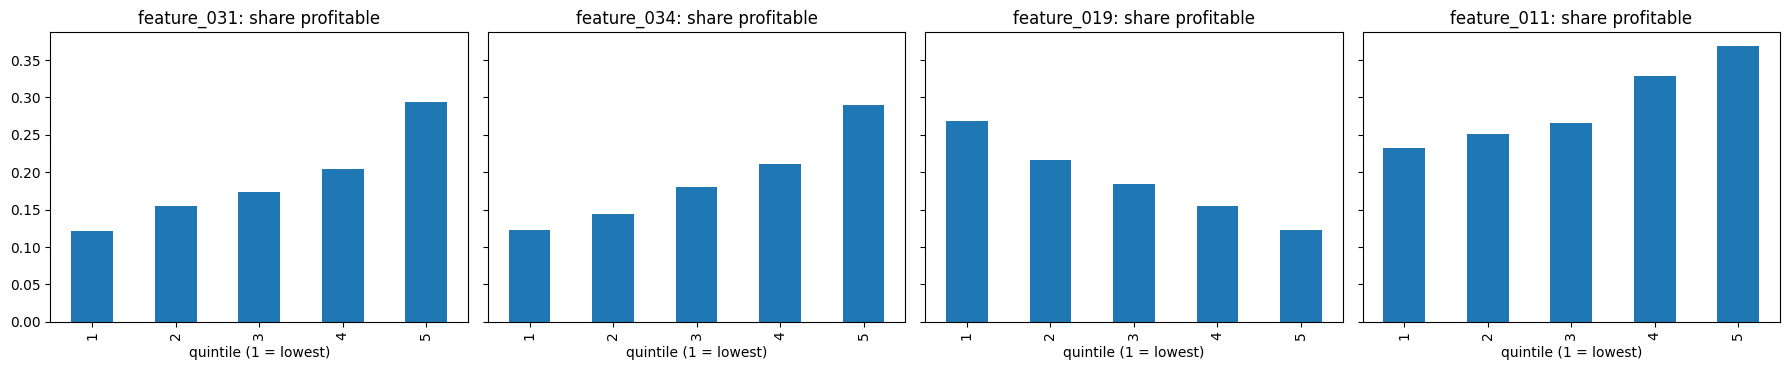

overall profitable share: 18.9%


In [ ]:
# ---- 5. Quintile lift tables for the top features -------------------------------------
top = [c for c in S.index if S.loc[c, 'q_fdr'] < .05][:4]
fig, ax = plt.subplots(1, len(top), figsize=(4.5 * len(top), 3.8), sharey=True)
for a, c in zip(np.atleast_1d(ax), top):
    q = pd.qcut(mf[c].rank(method='first'), 5, labels=[1, 2, 3, 4, 5])
    t = mf.groupby(q, observed=True).apply(lambda d: pd.Series({
        'any_payment': d.any24.mean(), 'pooled_rr24': d.p24.sum() / d.outst.sum(), 'profitable': d.profit.mean()}))
    display(t.round(3).rename_axis(c))
    t.profitable.plot.bar(ax=a, title=f'{c}: share profitable'); a.set_xlabel('quintile (1 = lowest)')
plt.tight_layout(); plt.show()
base = mf.profit.mean(); print(f'overall profitable share: {base:.1%}')

### Multicollinearity

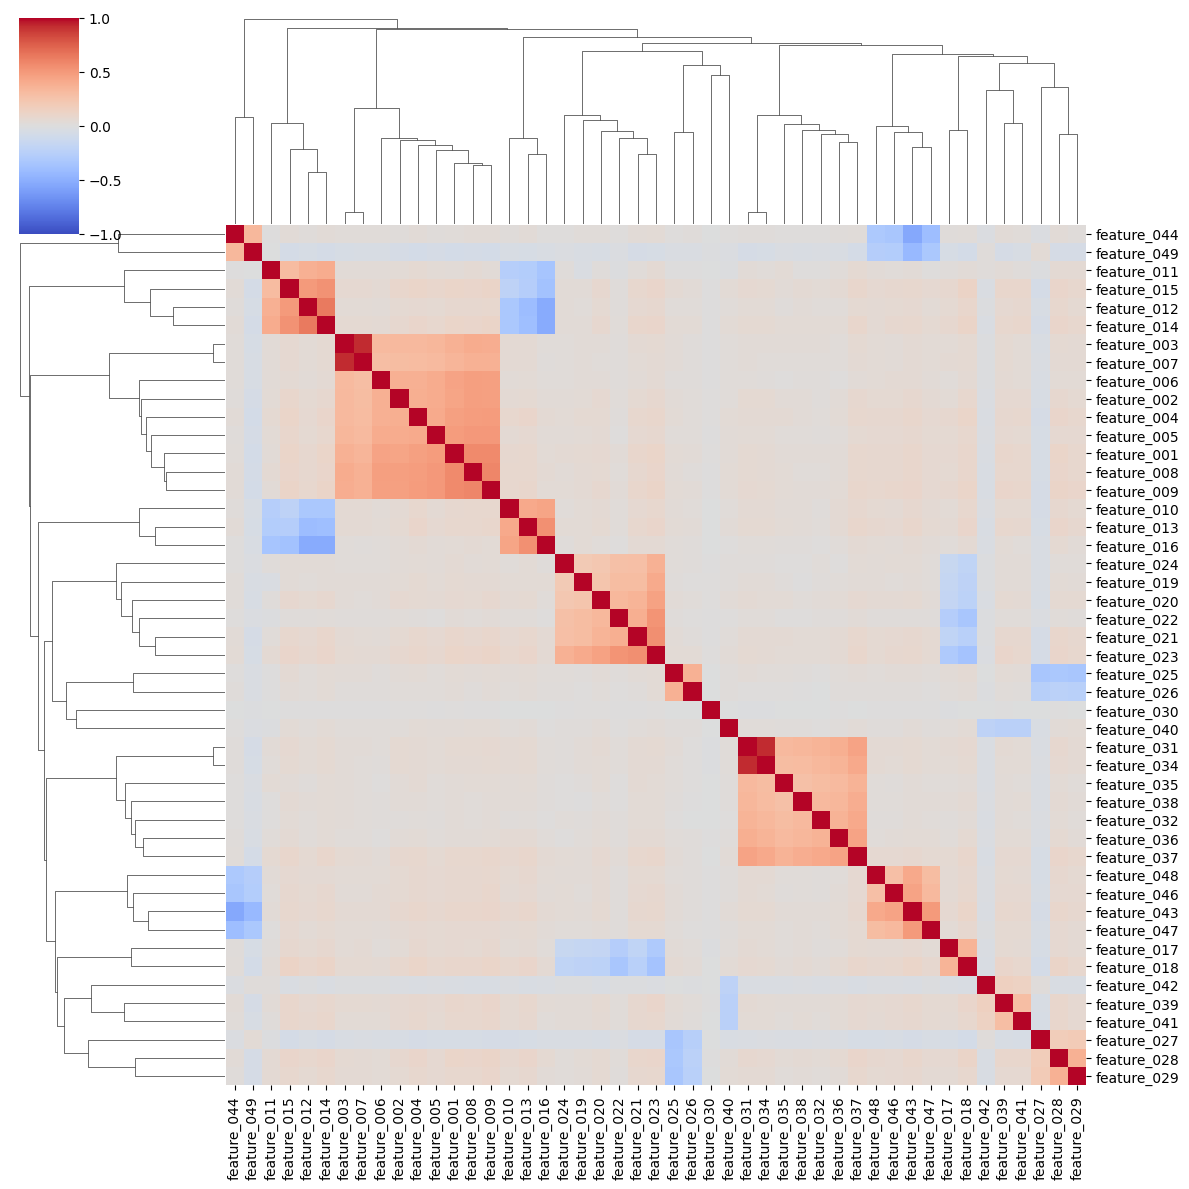

pairs |rho| > 0.6 (after dropping the exact duplicate):
  feature_003 ~ feature_007: 0.93  (Total credit turnover across all accounts, mo... | Total debit turnover across all accounts, mon...)
  feature_031 ~ feature_034: 0.92  (Credit bureau score at the last refresh befor... | Internal behavioural score at the last monthl...)
  feature_012 ~ feature_014: 0.64  (Maximum end-of-day total balance across all a... | Average payroll credit into the account, 6 mo...)

VIF (>5 worth a look, >10 problematic for linear/logistic models):


,VIF
feature_031,7.8
feature_034,7.4
feature_003,5.4
feature_007,5.3
feature_023,2.3
feature_008,2.1
feature_009,2.0
feature_043,1.9


In [ ]:
# ---- 6. Multicollinearity -----------------------------------------------------------------
C = feat[USE].corr(method='spearman')
sns.clustermap(C, cmap='coolwarm', center=0, vmin=-1, vmax=1, figsize=(12, 12),
               xticklabels=True, yticklabels=True)
plt.show()

pairs = [(a, b, round(C.loc[a, b], 2)) for i, a in enumerate(USE) for b in USE[i+1:] if abs(C.loc[a, b]) > .6]
print('pairs |rho| > 0.6 (after dropping the exact duplicate):')
for a, b, r_ in sorted(pairs, key=lambda t: -abs(t[2])):
    print(f'  {a} ~ {b}: {r_}  ({dic.loc[a, "description"][:45]}... | {dic.loc[b, "description"][:45]}...)')

Z = feat[USE].fillna(feat[USE].median()); Z = ((Z - Z.mean()) / Z.std()).assign(const=1.0)
vif = pd.Series([variance_inflation_factor(Z.values, i) for i in range(len(USE))], index=USE).sort_values(ascending=False)
print('\nVIF (>5 worth a look, >10 problematic for linear/logistic models):'); display(vif.head(8).round(1).to_frame('VIF'))

### Hypothesis tests

In [ ]:
# ---- 7. Hypothesis tests ----------------------------------------------------------------------
# (a) does recovery depend on the size of debt?
mf['bucket'] = pd.cut(mf.outst, [0, 2000, 4000, 8000, 15000, np.inf])
grp = [d.rr24.values for _, d in mf.groupby('bucket', observed=True)]
print('Kruskal-Wallis rr24 across outstanding buckets: H=%.1f p=%.1e' % kruskal(*grp))
print('Spearman(outst, rr24) = %.3f | Spearman(n_loans, rr24) = %.3f' %
      (spearmanr(mf.outst, mf.rr24)[0], spearmanr(mf.n_loans, mf.rr24)[0]))
ci = mf.groupby('bucket', observed=True).apply(lambda d: pd.Series({
    'n': len(d), 'any_payment': d.any24.mean(),
    'ci_lo': proportion_confint(d.any24.sum(), len(d), method='wilson')[0],
    'ci_hi': proportion_confint(d.any24.sum(), len(d), method='wilson')[1],
    'profitable': d.profit.mean()}))
display(ci.round(3))

# (b) is missingness informative?
for c in ['feature_011', 'feature_039']:
    m = mf[c].isna()
    p = mannwhitneyu(mf.rr24[m], mf.rr24[~m]).pvalue
    auc = roc_auc_score(mf.any24, m.astype(int))
    print(f'{c}: missing {m.mean():.1%} | any-payment {mf.any24[m].mean():.3f} vs {mf.any24[~m].mean():.3f} | '
          f'Mann-Whitney p={p:.1e} | AUC of the missing-flag={auc:.3f}')
print('-> add is_missing flags for 011 and 039; do NOT impute and forget.')

Kruskal-Wallis rr24 across outstanding buckets: H=40.1 p=4.1e-08
Spearman(outst, rr24) = -0.059 | Spearman(n_loans, rr24) = -0.103


/tmp/ipykernel_811/627128776.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ci = mf.groupby('bucket', observed=True).apply(lambda d: pd.Series({


,n,any_payment,ci_lo,ci_hi,profitable
bucket,,,,,
"(0.0, 2000.0]",2899.0,0.574,0.556,0.592,0.074
"(2000.0, 4000.0]",2431.0,0.539,0.519,0.559,0.204
"(4000.0, 8000.0]",2957.0,0.511,0.493,0.529,0.231
"(8000.0, 15000.0]",1987.0,0.523,0.501,0.545,0.235
"(15000.0, inf]",1286.0,0.498,0.471,0.526,0.257


feature_011: missing 85.7% | any-payment 0.516 vs 0.638 | Mann-Whitney p=3.9e-36 | AUC of the missing-flag=0.470
feature_039: missing 30.2% | any-payment 0.447 vs 0.571 | Mann-Whitney p=1.2e-56 | AUC of the missing-flag=0.448
-> add is_missing flags for 011 and 039; do NOT impute and forget.


### Stability

In [ ]:
# ---- 8. Stability ---------------------------------------------------------------------------------
def psi(ref, new, bins=10):
    ref, new = ref.dropna(), new.dropna()
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1))); edges[0], edges[-1] = -np.inf, np.inf
    a = np.histogram(ref, edges)[0] / len(ref) + 1e-4; b = np.histogram(new, edges)[0] / len(new) + 1e-4
    return float(((b - a) * np.log(b / a)).sum())

train_era = feat[feat.PERIOD <= mat.PERIOD.max()]      # periods that have matured (24m) outcomes
score_era = feat[feat.PERIOD >  mat.PERIOD.max()]      # periods with unmatured outcomes (what a live model will see)
print(f'matured-era rows: {len(train_era):,} | later rows: {len(score_era):,}')
P = pd.Series({c: psi(train_era[c], score_era[c]) for c in USE}).sort_values(ascending=False)
print('PSI < 0.1 stable | 0.1-0.25 moderate | > 0.25 major'); display(P.head(8).round(3).to_frame('PSI'))

# do the top signals keep their sign and strength over time?
mf['half'] = mf.PERIOD.str[:4] + 'H' + ((mf.PERIOD.str[5:].astype(int) > 6) + 1).astype(str)
top5 = list(S.index[:5])
stab = mf.groupby('half').apply(lambda d: pd.Series({c: spearmanr(d[c], d.rr24, nan_policy='omit')[0] for c in top5}))
stab['n'] = mf.groupby('half').size(); display(stab.round(3))

v = mf.groupby('half').apply(lambda d: pd.Series({'any_payment': d.any24.mean(), 'pooled_rr24': d.p24.sum() / d.outst.sum(),
                                                  'profitable': d.profit.mean()}))
display(v.round(3))

matured-era rows: 12,697 | later rows: 17,066
PSI < 0.1 stable | 0.1-0.25 moderate | > 0.25 major


,PSI
feature_007,0.101
feature_011,0.012
feature_018,0.003
feature_043,0.002
feature_002,0.002
feature_041,0.002
feature_036,0.001
feature_013,0.001


/tmp/ipykernel_811/3123580971.py:17: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  stab = mf.groupby('half').apply(lambda d: pd.Series({c: spearmanr(d[c], d.rr24, nan_policy='omit')[0] for c in top5}))


,feature_031,feature_034,feature_019,feature_011,feature_012,n
half,,,,,,
2023H1,0.196,0.192,-0.134,0.164,0.127,2838
2023H2,0.174,0.178,-0.109,0.129,0.127,3363
2024H1,0.160,0.156,-0.189,0.137,0.126,3943
2024H2,0.133,0.122,-0.098,0.126,0.136,1416


/tmp/ipykernel_811/3123580971.py:20: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  v = mf.groupby('half').apply(lambda d: pd.Series({'any_payment': d.any24.mean(), 'pooled_rr24': d.p24.sum() / d.outst.sum(),


,any_payment,pooled_rr24,profitable
half,,,
2023H1,0.549,0.136,0.203
2023H2,0.529,0.117,0.187
2024H1,0.536,0.125,0.192
2024H2,0.506,0.104,0.160
